# Graph — Analisis Dasar (statistik dan sentralitas)
**Kapan dipakai:** langkah pertama pada data graf: seberapa besar, seberapa rapat, simpul mana
yang paling penting. Hasilnya juga bisa jadi feature untuk model tabular.

**Langkah:**
1. Baca simpul dan sisi → graf networkx.
2. Statistik graf (kerapatan, komponen, clustering, diameter) dan sebaran derajat.
3. Sentralitas tiap simpul (derajat, PageRank, betweenness, closeness), simpan ke csv.

**Data demo:** Cora (sitasi 2.708 makalah) dan Karate Club (untuk gambar).

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/graph"   # GANTI saat lomba
NODES_CSV = f"{DATA_FOLDER}/cora/nodes.csv"
EDGES_CSV = f"{DATA_FOLDER}/cora/edges.csv"
KARATE_NODES_CSV = f"{DATA_FOLDER}/karate/nodes.csv"
KARATE_EDGES_CSV = f"{DATA_FOLDER}/karate/edges.csv"

NODE_ID_COL = "id"
SOURCE_COL = "source"
TARGET_COL = "target"
BETWEENNESS_SAMPLES = 200   # betweenness dihitung dari 200 simpul acak (versi penuh lambat)
TOP = 10
SEED = 42

## Baca data
Simpul ditambahkan dulu supaya simpul tanpa sisi tetap ikut dihitung.

In [3]:
nodes = pd.read_csv(NODES_CSV, usecols=[NODE_ID_COL, "label"])
edges = pd.read_csv(EDGES_CSV)
graph = nx.Graph()
graph.add_nodes_from(nodes[NODE_ID_COL])
graph.add_edges_from(zip(edges[SOURCE_COL], edges[TARGET_COL]))
graph.remove_edges_from(nx.selfloop_edges(graph))     # buang sisi dari simpul ke dirinya sendiri
print(graph.number_of_nodes(), "simpul,", graph.number_of_edges(), "sisi")
edges.head()

2708 simpul, 5278 sisi


,source,target
0,402,163
1,659,163
2,1696,163
3,2295,163
4,1274,163


## Statistik graf
Jalur terpendek dan diameter hanya bisa dihitung di komponen terbesar (LCC), karena antar
komponen tidak ada jalur.

In [4]:
components = list(nx.connected_components(graph))
largest = set()
for component in components:
    if len(component) > len(largest):
        largest = component
lcc = graph.subgraph(largest).copy()

degree_of = dict(graph.degree())        # simpul -> jumlah tetangga
stats = {}
stats["simpul"] = graph.number_of_nodes()
stats["sisi"] = graph.number_of_edges()
stats["kerapatan"] = nx.density(graph)
stats["derajat rata-rata"] = sum(degree_of.values()) / len(degree_of)
stats["jumlah komponen"] = len(components)
stats["komponen terbesar"] = len(lcc)
stats["clustering rata-rata"] = nx.average_clustering(graph)
stats["transitivitas"] = nx.transitivity(graph)
stats["jalur terpendek rata-rata (LCC)"] = nx.average_shortest_path_length(lcc)
stats["diameter (LCC)"] = nx.diameter(lcc)
stats = pd.Series(stats)
stats.to_csv("statistik.csv")
print(stats)

simpul                             2708.000000
sisi                               5278.000000
kerapatan                             0.001440
derajat rata-rata                     3.898080
jumlah komponen                      78.000000
komponen terbesar                  2485.000000
clustering rata-rata                  0.240673
transitivitas                         0.093497
jalur terpendek rata-rata (LCC)       6.310999
diameter (LCC)                       19.000000
dtype: float64


## Sebaran derajat
Sumbu y skala log: banyak simpul berderajat kecil, sedikit hub berderajat besar.

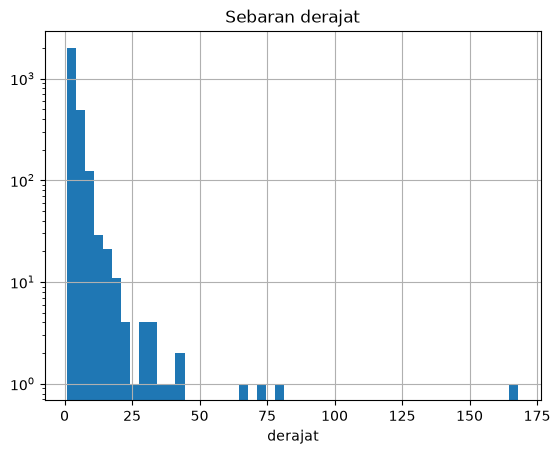

In [5]:
degrees = pd.Series(degree_of)
degrees.hist(bins=50)
plt.title("Sebaran derajat")
plt.xlabel("derajat")
plt.yscale("log")
plt.show()

## Sentralitas tiap simpul
- **Derajat:** jumlah tetangga.  **PageRank:** pengaruh (ditunjuk oleh simpul penting).
- **Betweenness:** peran jembatan antar kelompok.  **Closeness:** dekat ke semua simpul lain.

In [6]:
pagerank = nx.pagerank(graph)
betweenness = nx.betweenness_centrality(graph, k=BETWEENNESS_SAMPLES, seed=SEED)
closeness = nx.closeness_centrality(graph)

centrality = pd.DataFrame()
centrality["id"] = nodes[NODE_ID_COL]
centrality["label"] = nodes["label"]
centrality["degree"] = centrality["id"].map(degree_of)
centrality["pagerank"] = centrality["id"].map(pagerank)
centrality["betweenness"] = centrality["id"].map(betweenness)
centrality["closeness"] = centrality["id"].map(closeness)
centrality.to_csv("sentralitas.csv", index=False)
top_nodes = centrality.sort_values("pagerank", ascending=False)
top_nodes.head(TOP)

,id,label,degree,pagerank,betweenness,closeness
163,163,Genetic_Algorithms,168,0.012207,0.217703,0.222769
747,747,Neural_Networks,74,0.006250,0.098593,0.203243
427,427,Neural_Networks,65,0.005352,0.122620,0.219825
565,565,Reinforcement_Learning,78,0.005058,0.083950,0.221191
611,611,Neural_Networks,44,0.003631,0.063112,0.201411
74,74,Probabilistic_Methods,40,0.003185,0.111369,0.207631
552,552,Reinforcement_Learning,42,0.002792,0.011743,0.189159
430,430,Theory,36,0.002677,0.038948,0.207046
745,745,Neural_Networks,33,0.002638,0.029832,0.188487
638,638,Theory,34,0.002532,0.074310,0.212449


## Gambar graf kecil: Karate Club (warna = klub)

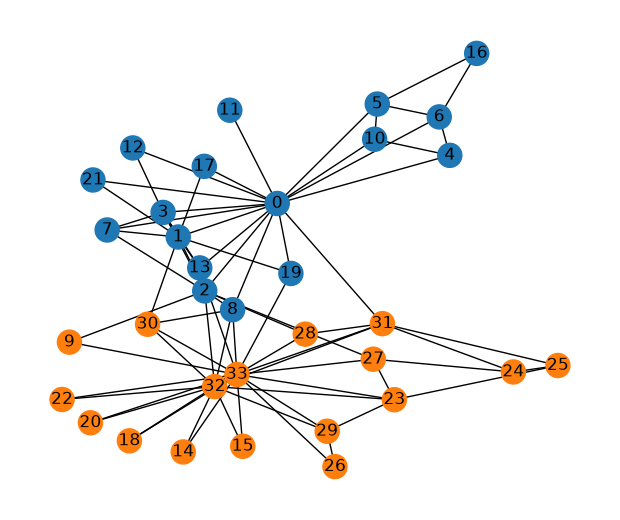

In [7]:
karate_nodes = pd.read_csv(KARATE_NODES_CSV)
karate_edges = pd.read_csv(KARATE_EDGES_CSV)
karate = nx.Graph()
karate.add_nodes_from(karate_nodes[NODE_ID_COL])
karate.add_edges_from(zip(karate_edges[SOURCE_COL], karate_edges[TARGET_COL]))
colors = []
for club in karate_nodes["club"]:
    if club == "Mr. Hi":
        colors.append("tab:blue")
    else:
        colors.append("tab:orange")
positions = nx.spring_layout(karate, seed=SEED)
plt.figure(figsize=(6, 5))
nx.draw(karate, positions, node_color=colors, with_labels=True)
plt.savefig("karate.png", dpi=120)
plt.show()